# TUTORIAL: AFINACIÓN DE HIPER-PARÁMETROS CON OPTUNA Y SCIKIT-LEARN

## 1. Lectura del set de datos

El set de datos a usar es una versión ligeramente modificada del set de datos ["heart failure prediction"](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction):

In [ ]:
import pandas as pd

df = pd.read_csv('enfermedad_cardiaca.csv')
df

,Edad,Sexo,tipo_dolor,presion_reposo,colesterol,nivel_azucar_ayunas,ecg_reposo,frec_card_max,angina_ejercicio,st,pendiente_st,enf_cardiaca
0,40,M,angina_atipica,140,289,0,normal,172,no,0.0,arriba,0
1,49,F,dolor_no_angina,160,180,0,normal,156,no,1.0,plano,1
2,37,M,angina_atipica,130,283,0,anormalidad_st,98,no,0.0,arriba,0
3,48,F,asintomatico,138,214,0,normal,108,si,1.5,plano,1
4,54,M,dolor_no_angina,150,195,0,normal,122,no,0.0,arriba,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,angina_tipica,110,264,0,normal,132,no,1.2,plano,1
914,68,M,asintomatico,144,193,1,normal,141,no,3.4,plano,1
915,57,M,asintomatico,130,131,0,normal,115,si,1.2,plano,1
916,57,F,angina_atipica,130,236,0,hipertrofia_vent_izq,174,no,0.0,plano,1


## 2. Exploración inicial del set de datos

In [ ]:
# Verifiquemos los tipos de datos y si hay o no datos faltantes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Edad                 918 non-null    int64  
 1   Sexo                 918 non-null    object 
 2   tipo_dolor           918 non-null    object 
 3   presion_reposo       918 non-null    int64  
 4   colesterol           918 non-null    int64  
 5   nivel_azucar_ayunas  918 non-null    int64  
 6   ecg_reposo           918 non-null    object 
 7   frec_card_max        918 non-null    int64  
 8   angina_ejercicio     918 non-null    object 
 9   st                   918 non-null    float64
 10  pendiente_st         918 non-null    object 
 11  enf_cardiaca         918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


Observaciones:

- Todos los registros están completos
- Tenemos variables numéricas como categóricas

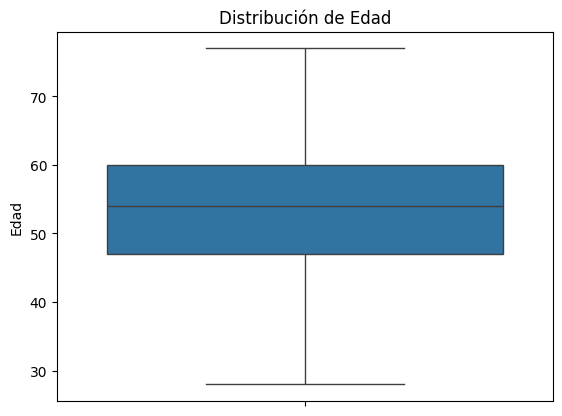

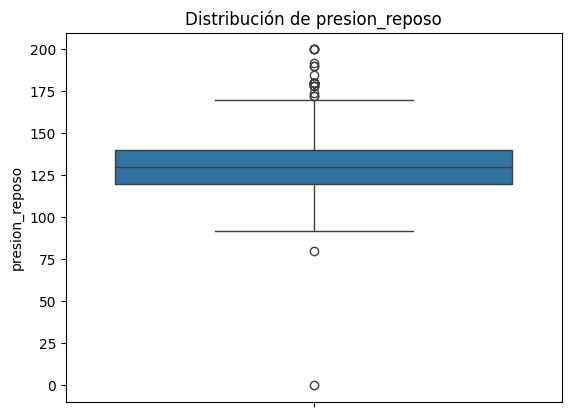

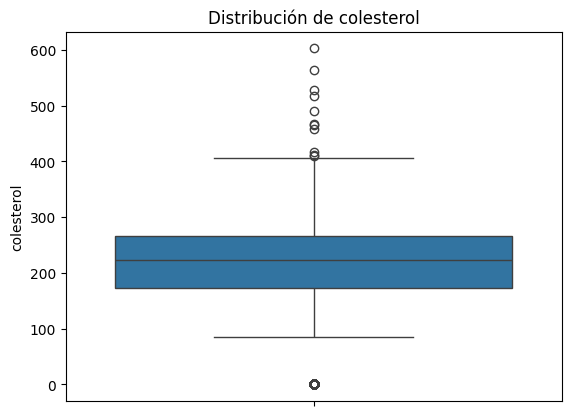

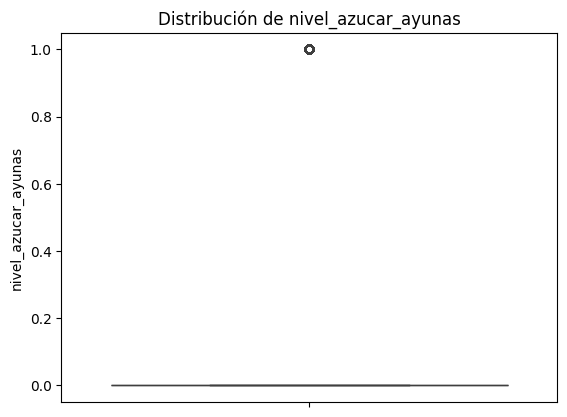

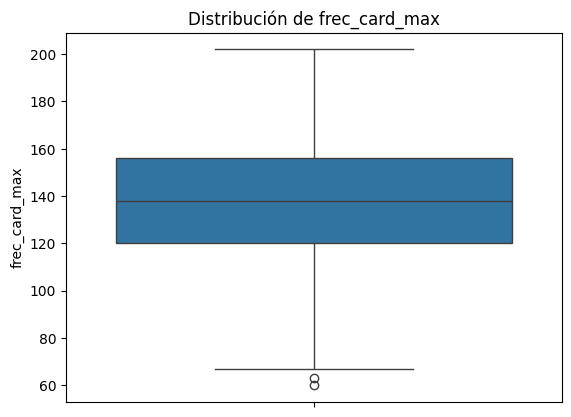

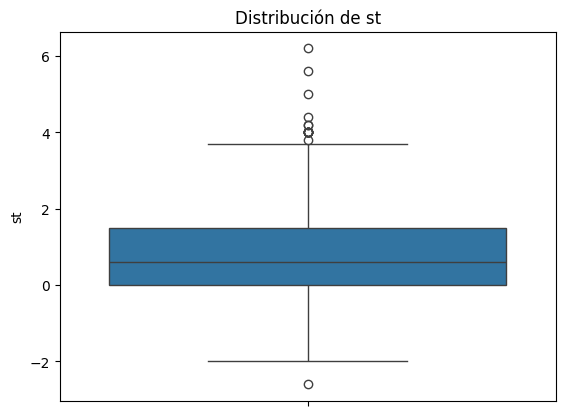

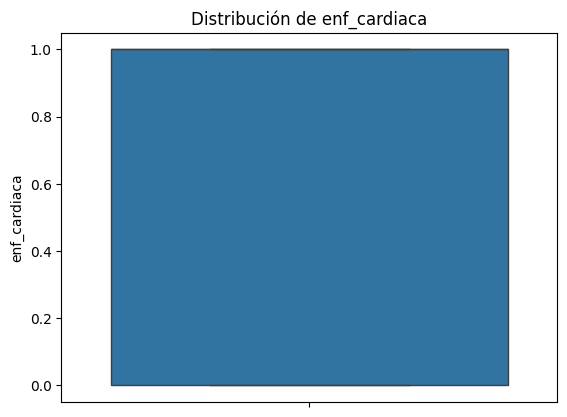

In [ ]:
# Graficar las variables numéricas
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    sns.boxplot(df[col])
    plt.title(f'Distribución de {col}')
    plt.show()

Observaciones:

- La variable "colesterol" contiene valores extremos (iguales a 0)

<Axes: ylabel='colesterol'>

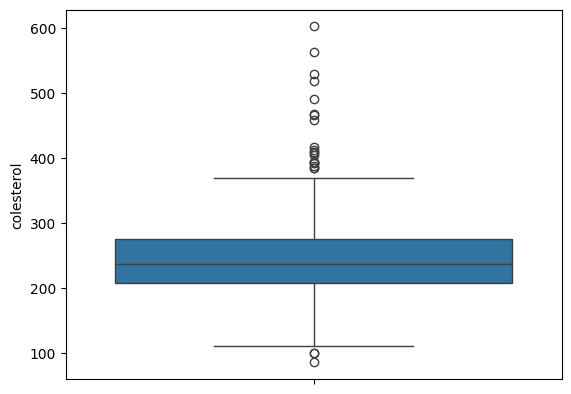

In [ ]:
# Eliminemos el outlier de colesterol
df = df[df['colesterol'] > 10]
sns.boxplot(df['colesterol'])

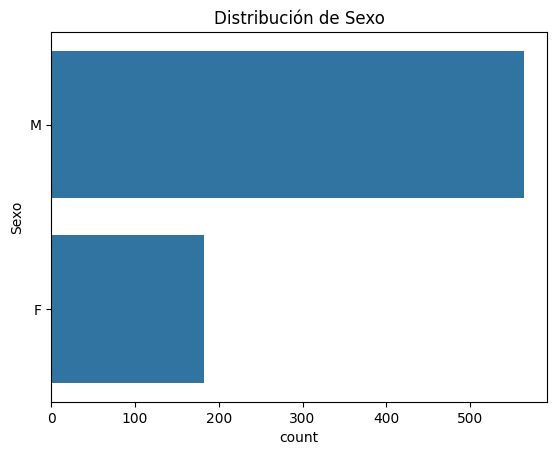

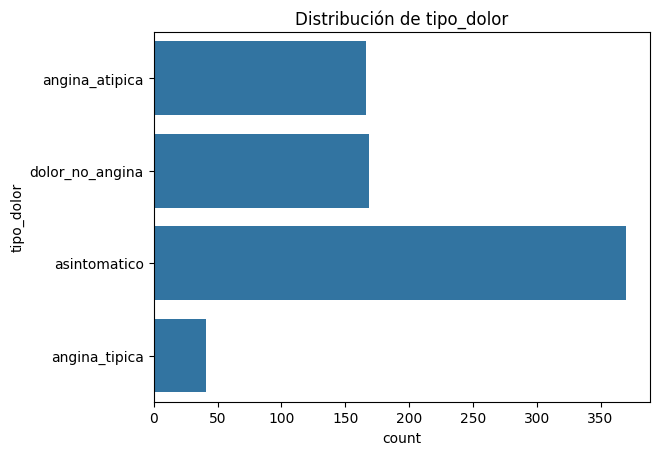

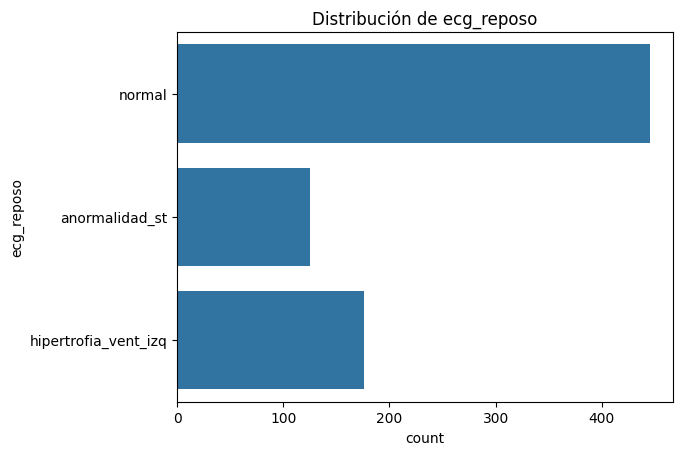

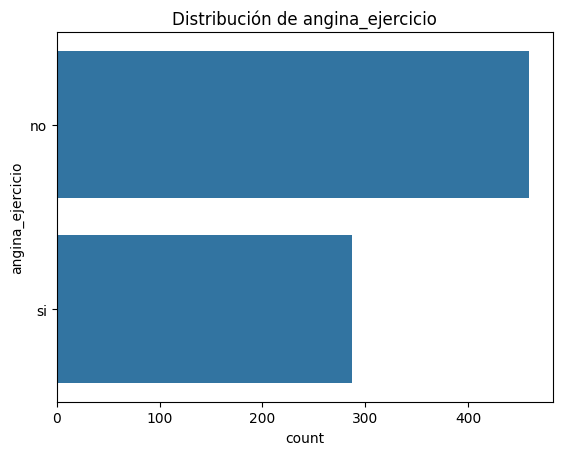

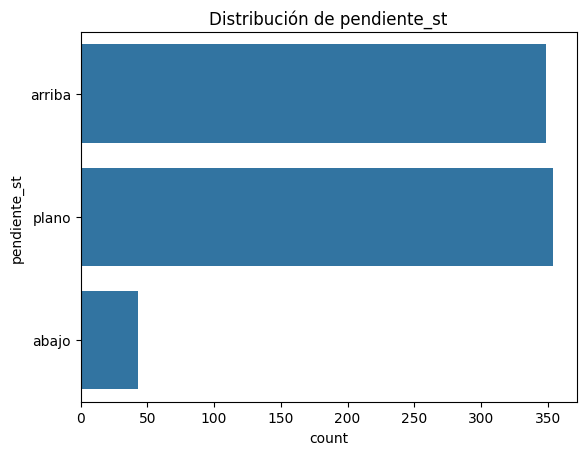

In [ ]:
# Veamos la distribución de las variables categóricas
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    sns.countplot(df[col])
    plt.title(f'Distribución de {col}')
    plt.show()

Observaciones:

- No se observan valores extremos (conteos extremadamente grandes o pequeños) en las variables categóricas

Text(0.5, 1.0, 'Distribución de la variable a predecir')

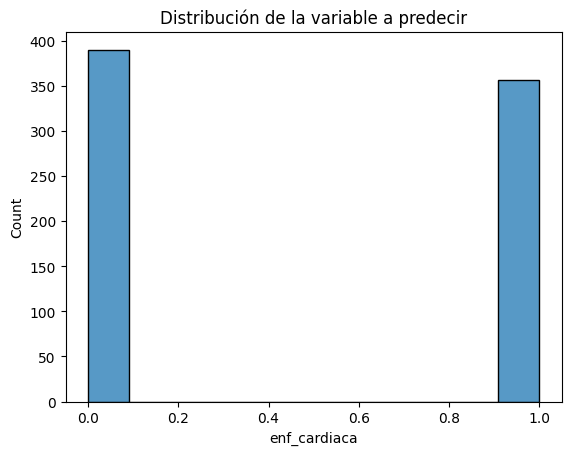

In [ ]:
# Y veamos la distribución de la variable a predecir
sns.histplot(df['enf_cardiaca'])
plt.title('Distribución de la variable a predecir')

Observación:

- La variable a predecir ("enf_cardiaca") está prácticamente balanceada

## 3. Análisis de correlación entre variables

Text(0.5, 1.0, 'Mapa de calor de correlación entre variables numéricas')

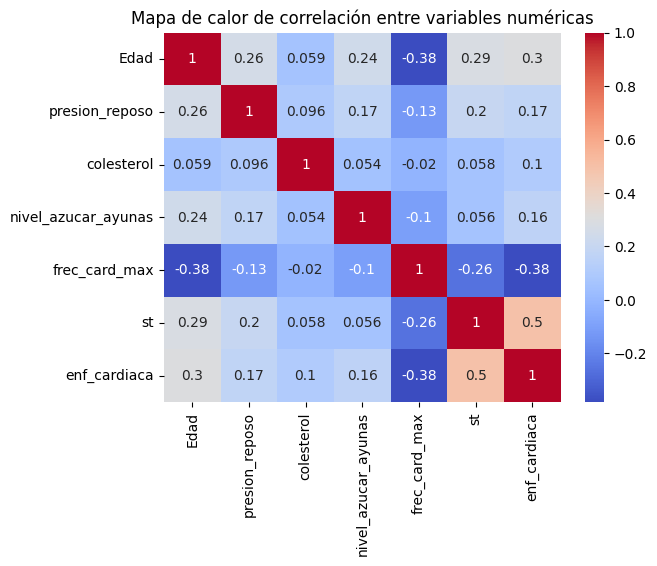

In [ ]:
# Mapa de calor de correlación entre variables numéricas
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Mapa de calor de correlación entre variables numéricas')

Observaciones:

- No se aprecian niveles de correlación relativamente altos (positivos o negativos, con magnitudes superiores a 0.7) entre las variables predictoras y la variable a predecir ("enf_cardiaca").
- Esto sugiere que las relaciones lineales fuertes entre variables son limitadas, por lo que podría ser útil explorar modelos que capturen relaciones no lineales.

## 4. Pre-procesamiento de los datos

In [ ]:
# Conformar arreglos X (entradas al modelo) y Y (variable a predecir)
X = df.drop('enf_cardiaca', axis=1)
Y = df['enf_cardiaca']
print(X.columns)
print(Y.name)

Index(['Edad', 'Sexo', 'tipo_dolor', 'presion_reposo', 'colesterol',
       'nivel_azucar_ayunas', 'ecg_reposo', 'frec_card_max',
       'angina_ejercicio', 'st', 'pendiente_st'],
      dtype='object')
enf_cardiaca


In [ ]:
# Codificar numéricamente las variables categóricas en "X"
X = pd.get_dummies(X, dtype='float32')
X

,Edad,presion_reposo,colesterol,nivel_azucar_ayunas,frec_card_max,st,Sexo_F,Sexo_M,tipo_dolor_angina_atipica,tipo_dolor_angina_tipica,tipo_dolor_asintomatico,tipo_dolor_dolor_no_angina,ecg_reposo_anormalidad_st,ecg_reposo_hipertrofia_vent_izq,ecg_reposo_normal,angina_ejercicio_no,angina_ejercicio_si,pendiente_st_abajo,pendiente_st_arriba,pendiente_st_plano
0,40,140,289,0,172,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,49,160,180,0,156,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
2,37,130,283,0,98,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,48,138,214,0,108,1.5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
4,54,150,195,0,122,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
914,68,144,193,1,141,3.4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
915,57,130,131,0,115,1.2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
916,57,130,236,0,174,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
# Subdividir el set de datos en entrenamiento (80%) y validación (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print(X_train.shape, Y_train.shape)
print(X_test.shape, Y_test.shape)

(596, 20) (596,)
(150, 20) (150,)


## 5. Modelo base (árbol de decisión)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(random_state=42)
arbol.fit(X_train, Y_train)

# Imprimir en pantalla hiper-parámetros de este modelo
params, values = zip(*arbol.get_params().items())
for param, value in zip(params, values):
    print(f"{param}: {value}")

ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: None
max_features: None
max_leaf_nodes: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
random_state: 42
splitter: best


In [ ]:
# Calcular el desempeño del modelo base usando validación cruzada
# (k-fold cross-validation con 5 "folds")
from sklearn.model_selection import cross_val_score

# Validación cruzada
scores = cross_val_score(arbol, X_train, Y_train, cv=5, scoring='accuracy')

# Imprimir puntajes individuales y promedio
print(f"Exactitudes individuales de cada 'fold': {scores}")
print(f"Exactitud promedio: {scores.mean()}")

Exactitudes individuales de cada 'fold': [0.78333333 0.77310924 0.81512605 0.69747899 0.76470588]
Exactitud promedio: 0.7667507002801119


## 6. Afinación con Optuna

In [ ]:
# Instalación de la librería
!pip install optuna


[notice] A new release of pip available: 22.3.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


### 6.1. Búsqueda Bayesiana

In [ ]:
# Optuna: crear función objetivo y en ella
# definir los hiper-parámetros a afinar

import optuna

def objective(trial):
    # Se afinarán max_depth, min_samples_split, min_samples_leaf y criterion
    # Definir estos hiperparámetros usando la variable "trial"
    max_depth = trial.suggest_int("max_depth", 5, 15) # Escoger aleatoriamente entre 1 y 15
    min_samples_split = trial.suggest_int("min_samples_split", 5, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 10, 20)
    criterion = trial.suggest_categorical("criterion", ["gini", "entropy"])

    # Crear árbol con hiper-parámetros variables
    modelo = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        criterion=criterion,
        random_state=42
    )

    # Validación cruzada
    scores = cross_val_score(modelo, X_train, Y_train, cv=5, scoring='accuracy')
    return scores.mean()

In [ ]:
from optuna.samplers import TPESampler

# Fijar semilla (para reproducibilidad)
sampler = TPESampler(seed=42)

# Afinación Bayesiana
estudio = optuna.create_study(direction="maximize", sampler=sampler)
estudio.optimize(objective, n_trials=50)

[I 2025-07-09 15:59:24,820] A new study created in memory with name: no-name-25e2c44f-67b8-49d9-8c54-6f5d3e57284b
[I 2025-07-09 15:59:24,841] Trial 0 finished with value: 0.8086974789915965 and parameters: {'max_depth': 9, 'min_samples_split': 20, 'min_samples_leaf': 18, 'criterion': 'gini'}. Best is trial 0 with value: 0.8086974789915965.
[I 2025-07-09 15:59:24,855] Trial 1 finished with value: 0.8154341736694677 and parameters: {'max_depth': 6, 'min_samples_split': 5, 'min_samples_leaf': 19, 'criterion': 'entropy'}. Best is trial 1 with value: 0.8154341736694677.
[I 2025-07-09 15:59:24,868] Trial 2 finished with value: 0.8154341736694677 and parameters: {'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 19, 'criterion': 'gini'}. Best is trial 1 with value: 0.8154341736694677.
[I 2025-07-09 15:59:24,882] Trial 3 finished with value: 0.815420168067227 and parameters: {'max_depth': 7, 'min_samples_split': 9, 'min_samples_leaf': 15, 'criterion': 'gini'}. Best is trial 1 with v

In [ ]:
# Verificar mejores hiper-parámetros y desempeño obtenido
print("Mejor modelo (búsqueda Bayesiana):")
print("  Exactitud validación cruzada: ", estudio.best_trial.value)
print("  Parámetros: ")
for key, value in estudio.best_trial.params.items():
    print(f"    {key}: {value}")

Mejor modelo (búsqueda Bayesiana):
  Exactitud validación cruzada:  0.8372829131652659
  Parámetros: 
    max_depth: 8
    min_samples_split: 16
    min_samples_leaf: 10
    criterion: entropy


In [ ]:
# Entrenar modelo afinado con los mejores hiper-parámetros
mejores_hiperparams = estudio.best_trial.params

modelo_af1 = DecisionTreeClassifier(
    **mejores_hiperparams,
    random_state=42
)
modelo_af1.fit(X_train, Y_train)

# Y confirmar el desempeño de este modelo
scores = cross_val_score(modelo_af1, X_train, Y_train, cv=5, scoring='accuracy')
print(f"Exactitud modelo afinado (búsqueda Bayesiana): {scores.mean()}")

Exactitud modelo afinado (búsqueda Bayesiana): 0.8372829131652659


### 6.2. Búsqueda aleatoria (RandomSearch)

In [ ]:
# Afinar el modelo usando búsqueda aleatoria
from optuna.samplers import RandomSampler

estudio = optuna.create_study(
    direction="maximize",
    sampler=RandomSampler(seed=42)
)
estudio.optimize(objective, n_trials=50)

[I 2025-07-09 15:59:26,035] A new study created in memory with name: no-name-645ca127-a12e-4192-8772-b83ecc9d98b6
[I 2025-07-09 15:59:26,051] Trial 0 finished with value: 0.8086974789915965 and parameters: {'max_depth': 9, 'min_samples_split': 20, 'min_samples_leaf': 18, 'criterion': 'gini'}. Best is trial 0 with value: 0.8086974789915965.
[I 2025-07-09 15:59:26,064] Trial 1 finished with value: 0.8154341736694677 and parameters: {'max_depth': 6, 'min_samples_split': 5, 'min_samples_leaf': 19, 'criterion': 'entropy'}. Best is trial 1 with value: 0.8154341736694677.
[I 2025-07-09 15:59:26,078] Trial 2 finished with value: 0.8154341736694677 and parameters: {'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 19, 'criterion': 'gini'}. Best is trial 1 with value: 0.8154341736694677.
[I 2025-07-09 15:59:26,093] Trial 3 finished with value: 0.815420168067227 and parameters: {'max_depth': 7, 'min_samples_split': 9, 'min_samples_leaf': 15, 'criterion': 'gini'}. Best is trial 1 with v

In [ ]:
# Verificar mejores hiper-parámetros y desempeño obtenido
print("Mejor modelo (RandomSearch):")
print("  Exactitud validación cruzada: ", estudio.best_trial.value)
print("  Parámetros: ")
for key, value in estudio.best_trial.params.items():
    print(f"    {key}: {value}")

# Entrenar modelo afinado con los mejores hiper-parámetros
mejores_hiperparams = estudio.best_trial.params

modelo_af2 = DecisionTreeClassifier(
    **mejores_hiperparams,
    random_state=42
)
modelo_af2.fit(X_train, Y_train)

# E imprimir desempeño obtenido
scores = cross_val_score(modelo_af2, X_train, Y_train, cv=5, scoring='accuracy')
print(f"Exactitud modelo afinado (met. RandomSampler): {scores.mean()}")

Mejor modelo (RandomSearch):
  Exactitud validación cruzada:  0.8322408963585433
  Parámetros: 
    max_depth: 11
    min_samples_split: 7
    min_samples_leaf: 10
    criterion: entropy
Exactitud modelo afinado (met. RandomSampler): 0.8322408963585433


### 6.3. Búsqueda exhaustiva (GridSearch)

In [ ]:
# Definir el espacio de búsqueda
espacio_busqueda = {
    "max_depth": [5,15],
    "min_samples_split": [5,12,20],
    "min_samples_leaf": [10, 20],
    "criterion": ["gini", "entropy"]
}

# Número de combinaciones en el espacio de búsqueda
num_trials = np.prod([len(values) for values in espacio_busqueda.values()])
print(f"Número de combinaciones en el espacio de búsqueda: {num_trials}")

Número de combinaciones en el espacio de búsqueda: 24


In [ ]:
# Afinación usando GridSearch
from optuna.samplers import GridSampler

estudio = optuna.create_study(
    direction="maximize",
    sampler=GridSampler(espacio_busqueda)
)
estudio.optimize(objective)

[I 2025-07-09 15:59:26,789] A new study created in memory with name: no-name-e62726d9-81bd-4a42-9040-b13eea886408
[I 2025-07-09 15:59:26,803] Trial 0 finished with value: 0.8221568627450979 and parameters: {'max_depth': 15, 'min_samples_split': 20, 'min_samples_leaf': 20, 'criterion': 'gini'}. Best is trial 0 with value: 0.8221568627450979.
[I 2025-07-09 15:59:26,816] Trial 1 finished with value: 0.8221568627450979 and parameters: {'max_depth': 15, 'min_samples_split': 12, 'min_samples_leaf': 20, 'criterion': 'gini'}. Best is trial 0 with value: 0.8221568627450979.
[I 2025-07-09 15:59:26,829] Trial 2 finished with value: 0.8221568627450979 and parameters: {'max_depth': 15, 'min_samples_split': 12, 'min_samples_leaf': 20, 'criterion': 'entropy'}. Best is trial 0 with value: 0.8221568627450979.
[I 2025-07-09 15:59:26,844] Trial 3 finished with value: 0.8221568627450979 and parameters: {'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 10, 'criterion': 'entropy'}. Best is trial

In [ ]:
# Verificar mejores hiper-parámetros y desempeño obtenido
print("Mejor modelo (GridSearch):")
print("  Exactitud validación cruzada: ", estudio.best_trial.value)
print("  Parámetros: ")
for key, value in estudio.best_trial.params.items():
    print(f"    {key}: {value}")

# Entrenar modelo afinado con los mejores hiper-parámetros
mejores_hiperparams = estudio.best_trial.params

modelo_af3 = DecisionTreeClassifier(
    **mejores_hiperparams,
    random_state=42
)
modelo_af3.fit(X_train, Y_train)

# E imprimir desempeño obtenido
scores = cross_val_score(modelo_af3, X_train, Y_train, cv=5, scoring='accuracy')
print(f"Exactitud modelo afinado (met. GridSearch): {scores.mean()}")

Mejor modelo (GridSearch):
  Exactitud validación cruzada:  0.8322408963585433
  Parámetros: 
    max_depth: 15
    min_samples_split: 20
    min_samples_leaf: 10
    criterion: entropy
Exactitud modelo afinado (met. GridSearch): 0.8322408963585433
